<a href="https://colab.research.google.com/github/romanotancredi/equity-investment-research-portfolio/blob/main/01-equity-performance-and-risk/analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:

!pip install -q yfinance pandas numpy matplotlib


In [3]:

import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

tickers = ["VTI", "VEA", "VWO", "VT"]

prices = yf.download(
    tickers,
    start="2020-01-01",
    end="2026-11-01",
    auto_adjust=True,
    progress=False
)["Close"]

prices = prices[tickers].dropna()

print("Observations:", len(prices))
print("Start:", prices.index.min())
print("End:", prices.index.max())

display(prices.head())


Observations: 1717
Start: 2020-01-02 00:00:00
End: 2026-10-30 00:00:00


Ticker,VTI,VEA,VWO,VT
Date,,,,
2020-01-02,149.778320,36.584690,37.796169,71.800972
2020-01-03,148.825058,36.139923,37.123756,71.151497
2020-01-06,149.333511,36.263466,37.057343,71.414833
2020-01-07,148.979431,36.205811,37.040737,71.195404
2020-01-08,149.714813,36.255238,37.206779,71.485016


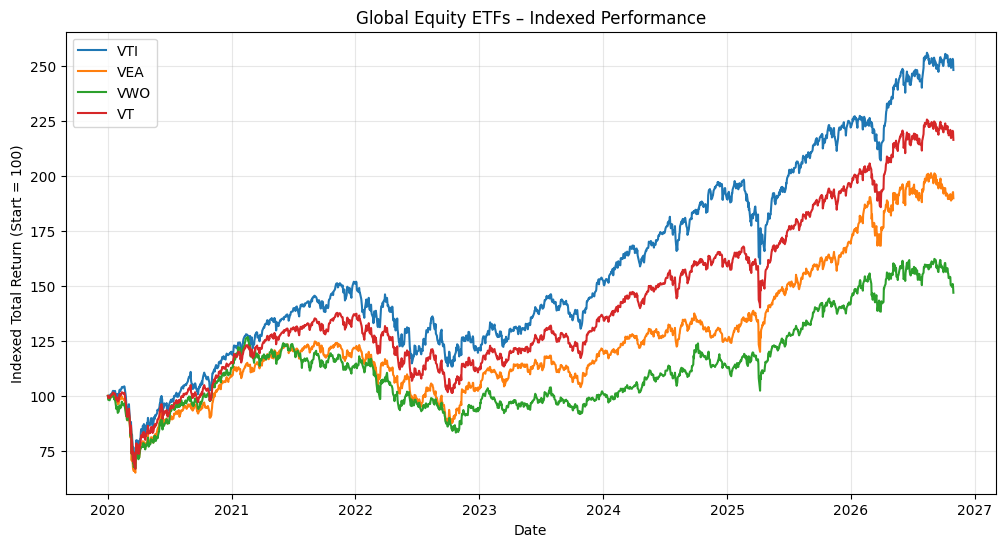

In [4]:

# Normalise all ETF prices to 100
indexed_prices = prices / prices.iloc[0] * 100

plt.figure(figsize=(12, 6))

for ticker in tickers:
    plt.plot(
        indexed_prices.index,
        indexed_prices[ticker],
        label=ticker
    )

plt.title("Global Equity ETFs – Indexed Performance")
plt.xlabel("Date")
plt.ylabel("Indexed Total Return (Start = 100)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()
